# Project 14: Identifying Bird Species from Photographs

## Group 12

### Mohamed Alromaithi 100060448

### Zayed Alnuaimi 100061300

---

## 1. Environment and configuration (Kaggle or PyCharm)

Import this notebook into Kaggle, attach CUB-200-2011 with **Add Input**, and choose **Run All**. The input display name can be anything; the files must contain CUB-200-2011. The notebook detects Kaggle paths automatically and remains self-contained.

Sections 1–7 prepare data. Sections 8–15 run the four model configurations, tune on validation data, evaluate the held-out test set, and generate analysis artifacts. Enable Kaggle Internet for the initial EfficientNet weight download, or attach the official checkpoint and set WEIGHTS_FILE in Section 8. A GPU is recommended for CNN extraction; CPU is supported.

All 200 species and the fixed seed-42 splits are retained. Local setup and reproduction instructions are in README.md.

In [1]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
from time import perf_counter
import hashlib
import json
import os
import platform
import random
import sys
import tarfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from sklearn.model_selection import train_test_split

def detect_runtime(kaggle_root=Path('/kaggle'), start_dir=None):
    """Separate read-only inputs from writable outputs on Kaggle."""
    if (kaggle_root / 'input').is_dir() and (kaggle_root / 'working').is_dir():
        return 'kaggle', kaggle_root / 'working', kaggle_root / 'input'
    start = Path.cwd() if start_dir is None else Path(start_dir)
    project = next(
        (folder for folder in [start, *start.parents]
         if (folder / 'cosc434-group12-project.ipynb').is_file()),
        start,
    )
    return 'local', project, project


RUNTIME, PROJECT_ROOT, INPUT_ROOT = detect_runtime()
# Usually leave this as None. If multiple datasets match, set the exact archive
# path or the folder containing images.txt, classes.txt, and the images folder.
DATASET_SOURCE = None

SEED = 42
VALIDATION_FRACTION = 0.20
EXPECTED_IMAGES = 11788
EXPECTED_CLASSES = 200
EXPECTED_OFFICIAL_TRAIN = 5994
EXPECTED_OFFICIAL_TEST = 5794

DATA_DIR = PROJECT_ROOT / 'data'
DATASET_DIR = DATA_DIR / 'CUB_200_2011'
SPLITS_DIR = PROJECT_ROOT / 'splits'
CACHE_DIR = PROJECT_ROOT / 'cache'
CHECKS_DIR = PROJECT_ROOT / 'results' / 'data_checks'
for folder in (DATA_DIR, SPLITS_DIR, CACHE_DIR, CHECKS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
timings = {}
package_names = [
    'numpy', 'pandas', 'Pillow', 'matplotlib', 'scikit-learn',
    'scikit-image', 'ipykernel', 'jupyterlab',
]
def installed_version(package):
    # Reporting optional packages must not prevent a Kaggle run.
    try:
        return version(package)
    except PackageNotFoundError:
        return 'not installed (optional for data preparation)'


environment = {
    'runtime': RUNTIME,
    'python': platform.python_version(),
    'platform': platform.platform(),
    'processor': platform.processor(),
    'logical_cpu_count': os.cpu_count(),
    'packages': {name: installed_version(name) for name in package_names},
}

print('Python executable:', sys.executable)
print('Runtime:', RUNTIME)
print('Input search folder:', INPUT_ROOT)
print('Writable output folder:', PROJECT_ROOT)
print('Random seed:', SEED)
display(pd.Series(environment['packages'], name='version').to_frame())

Python executable: C:\Users\dalma\PycharmProjects\MachineLearning_Project\.venv\Scripts\python.exe
Runtime: local
Input search folder: C:\Users\dalma\PycharmProjects\MachineLearning_Project
Writable output folder: C:\Users\dalma\PycharmProjects\MachineLearning_Project
Random seed: 42


,version
numpy,2.5.4
pandas,3.1.1
Pillow,13.0.0
matplotlib,3.11.2
scikit-learn,1.9.1
scikit-image,0.26.0
ipykernel,7.4.0
jupyterlab,4.6.5


## 2. Locate and prepare CUB-200-2011

The notebook searches attached Kaggle inputs recursively, so the dataset slug does not need to be hard-coded. Supported archive names are `CUB_200_2011.tgz`, `BirdImages_Dataset.tgz`, and their `.tar.gz` equivalents. A complete, already-extracted CUB folder is also supported and is read directly from the input mount.

Archives are extracted into the writable `data/CUB_200_2011/` folder under the output root. No files are written into Kaggle inputs. The original [CUB-200-2011 archive](https://www.vision.caltech.edu/datasets/cub_200_2011/) is required; the optional NABirds collection is a different dataset.

We record an archive hash when an archive is available, and metadata hashes in both cases. Completed extractions are reused on reruns. If multiple matching archives or extracted folders exist, set `DATASET_SOURCE` in Section 1 to choose explicitly.

In [2]:
def sha256_file(path):
    """Hash a file without loading the whole file into memory."""
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


required_metadata = [
    'images.txt', 'classes.txt', 'image_class_labels.txt', 'train_test_split.txt',
]
archive_names = {
    'cub_200_2011.tgz', 'birdimages_dataset.tgz',
    'cub_200_2011.tar.gz', 'birdimages_dataset.tar.gz',
}


def is_dataset_folder(folder):
    return (
        folder.is_dir()
        and (folder / 'images').is_dir()
        and all((folder / name).is_file() for name in required_metadata)
    )


def find_dataset_source(search_root, recursive=False, override=None):
    """Locate a supported archive, or metadata beside an extracted images folder."""
    if override is not None:
        source = Path(override).expanduser()
        if is_dataset_folder(source) or (
            source.is_file() and source.name.lower().endswith(('.tgz', '.tar.gz'))
        ):
            return source
        raise FileNotFoundError('DATASET_SOURCE must point to a CUB archive or a complete CUB folder.')

    if recursive:
        archives = sorted({
            path for pattern in ('*.tgz', '*.tar.gz')
            for path in search_root.rglob(pattern)
            if path.is_file() and path.name.lower() in archive_names
        })
    else:
        archives = sorted({
            path for folder in (search_root, search_root / 'data') if folder.is_dir()
            for path in folder.iterdir()
            if path.is_file() and path.name.lower() in archive_names
        })
    # Prefer an archive when both representations are present.
    candidates = archives
    if not candidates:
        metadata_files = (
            search_root.rglob('images.txt') if recursive else
            [folder / 'images.txt' for folder in (
                search_root, search_root / 'CUB_200_2011',
                search_root / 'data' / 'CUB_200_2011',
            )]
        )
        candidates = sorted({
            path.parent for path in metadata_files if is_dataset_folder(path.parent)
        })
    if len(candidates) > 1:
        choices = '\n'.join(str(path) for path in candidates)
        raise ValueError(f'Multiple CUB sources found. Set DATASET_SOURCE to one path:\n{choices}')
    if not candidates:
        raise FileNotFoundError(
            f'No CUB-200-2011 dataset found under {search_root}. '
            'On Kaggle, use Add Input to attach the CUB archive or extracted dataset. '
            'Locally, place the archive beside the notebook. NABirds alone is not sufficient.'
        )
    return candidates[0]


def prepare_dataset(source, data_dir):
    """Read an extracted input directly, or extract an archive into writable storage."""
    if source.is_dir():
        print('Reading the already-extracted dataset:', source)
        return source, {
            'source_type': 'extracted_directory', 'source_path': str(source),
            'archive_name': None, 'archive_sha256': None,
        }

    print('Checking archive:', source, flush=True)
    digest = sha256_file(source)
    dataset_dir = data_dir / 'CUB_200_2011'
    completion_path = data_dir / 'extraction_complete.json'
    previous = (
        json.loads(completion_path.read_text(encoding='utf-8'))
        if completion_path.exists() else None
    )
    if previous and previous['archive_sha256'] != digest:
        raise ValueError('The archive differs from the extracted data. Use a separate output folder.')

    if previous and is_dataset_folder(dataset_dir):
        print('Matching extraction found; reusing existing files.')
    else:
        extracted_files = 0
        data_dir.mkdir(parents=True, exist_ok=True)
        with tarfile.open(source, mode='r|gz') as bundle:
            for member in bundle:
                member_path = PurePosixPath(member.name)
                if member_path.is_absolute() or '..' in member_path.parts:
                    raise ValueError(f'Unsafe archive member: {member.name}')
                if not member_path.parts or member_path.parts[0] != 'CUB_200_2011':
                    continue
                if not (member.isdir() or member.isfile()):
                    raise ValueError(f'Unexpected archive member type: {member.name}')
                bundle.extract(member, path=data_dir, filter='data')
                extracted_files += int(member.isfile())
                if member.isfile() and extracted_files % 2000 == 0:
                    print(f'Extracted {extracted_files:,} files...', flush=True)
        if not is_dataset_folder(dataset_dir):
            raise FileNotFoundError('The archive does not contain the complete CUB_200_2011 dataset.')
        completion_path.write_text(
            json.dumps({
                'archive_sha256': digest, 'dataset_directory': 'CUB_200_2011',
                'extracted_files': extracted_files,
            }, indent=2), encoding='utf-8',
        )
        print(f'Extraction complete: {extracted_files:,} files.')

    return dataset_dir, {
        'source_type': 'archive', 'source_path': str(source),
        'archive_name': source.name, 'archive_sha256': digest,
    }


def image_file(relative_path):
    """Resolve the unchanged manifest paths against the actual dataset location."""
    suffix = PurePosixPath(relative_path).relative_to('data/CUB_200_2011/images')
    path = DATASET_DIR / 'images' / Path(*suffix.parts)
    if not path.resolve().is_relative_to((DATASET_DIR / 'images').resolve()):
        raise ValueError('Image path is outside the dataset image directory.')
    return path


started = perf_counter()
dataset_source = find_dataset_source(
    INPUT_ROOT, recursive=(RUNTIME == 'kaggle'), override=DATASET_SOURCE,
)
DATASET_DIR, dataset_provenance = prepare_dataset(dataset_source, DATA_DIR)
archive_sha256 = dataset_provenance['archive_sha256']
timings['archive_check_and_extraction_seconds'] = round(perf_counter() - started, 3)
print('Archive SHA-256:', archive_sha256 or 'not available for an extracted input')
print('Dataset folder:', DATASET_DIR)

Checking archive: C:\Users\dalma\PycharmProjects\MachineLearning_Project\BirdImages_Dataset.tgz
Matching extraction found; reusing existing files.
Archive SHA-256: 0c685df5597a8b24909f6a7c9db6d11e008733779a671760afef78feb49bf081
Dataset folder: C:\Users\dalma\PycharmProjects\MachineLearning_Project\data\CUB_200_2011


## 3. Verify metadata and build the image table

Join metadata using **image IDs**, not row positions or directory order. Check unique IDs and paths, complete labels, 200 species, and the supplied 5,994/5,794 training/test separation.

Class IDs remain the original **1–200**. Saved image paths keep the same canonical `data/CUB_200_2011/images/...` format on both platforms. Use `image_file(row.relative_path)` to resolve each path; this also works when the actual images remain under a read-only Kaggle input mount.

In [3]:
started = perf_counter()
images = pd.read_csv(
    DATASET_DIR / 'images.txt', sep=r'\s+', header=None,
    names=['image_id', 'image_path'],
)
labels = pd.read_csv(
    DATASET_DIR / 'image_class_labels.txt', sep=r'\s+', header=None,
    names=['image_id', 'class_id'],
)
official_split = pd.read_csv(
    DATASET_DIR / 'train_test_split.txt', sep=r'\s+', header=None,
    names=['image_id', 'is_training_image'],
)
classes = pd.read_csv(
    DATASET_DIR / 'classes.txt', sep=r'\s+', header=None,
    names=['class_id', 'class_name'],
)

for name, table in [('images', images), ('labels', labels), ('split', official_split)]:
    assert len(table) == EXPECTED_IMAGES, (
        f'Expected CUB-200-2011 ({EXPECTED_IMAGES} images); found {len(table)} rows in {name}. '
        'Check that the input is CUB-200-2011, not the optional NABirds dataset.'
    )
    assert table['image_id'].is_unique, f'Duplicate image IDs in {name}.'
    assert not table.isna().any().any(), f'Missing values in {name}.'
assert set(images['image_id']) == set(labels['image_id']) == set(official_split['image_id'])
assert images['image_path'].is_unique, 'Multiple image IDs refer to the same path.'
assert len(classes) == EXPECTED_CLASSES and classes['class_id'].is_unique
assert not classes.isna().any().any() and classes['class_name'].is_unique
assert set(classes['class_id']) == set(range(1, EXPECTED_CLASSES + 1))
assert set(labels['class_id']) == set(classes['class_id'])
assert set(official_split['is_training_image']) == {0, 1}

manifest = (
    images.merge(labels, on='image_id', validate='one_to_one')
    .merge(official_split, on='image_id', validate='one_to_one')
    .merge(classes, on='class_id', validate='many_to_one')
    .sort_values('image_id')
    .reset_index(drop=True)
)
manifest['official_split'] = np.where(
    manifest['is_training_image'].eq(1), 'train', 'test',
)
manifest['relative_path'] = (
    'data/CUB_200_2011/images/' + manifest['image_path']
)
# The class directory should agree with the metadata label.
assert (manifest['image_path'].str.split('/').str[0] == manifest['class_name']).all()
manifest = manifest[
    ['image_id', 'relative_path', 'class_id', 'class_name', 'official_split']
]
official_counts = manifest['official_split'].value_counts().to_dict()
assert official_counts == {'train': EXPECTED_OFFICIAL_TRAIN, 'test': EXPECTED_OFFICIAL_TEST}
metadata_sha256 = {
    name: sha256_file(DATASET_DIR / name) for name in required_metadata
}
timings['metadata_verification_seconds'] = round(perf_counter() - started, 3)

print(f'Verified {len(manifest):,} image records across {len(classes)} species.')
display(manifest.groupby('official_split').agg(
    images=('image_id', 'size'), species=('class_id', 'nunique'),
))
display(manifest.loc[manifest['official_split'].eq('train')].head())

Verified 11,788 image records across 200 species.


,images,species
official_split,,
test,5794,200
train,5994,200


,image_id,relative_path,class_id,class_name,official_split
1,2,data/CUB_200_2011/images/001.Black_footed_Alba...,1,001.Black_footed_Albatross,train
3,4,data/CUB_200_2011/images/001.Black_footed_Alba...,1,001.Black_footed_Albatross,train
4,5,data/CUB_200_2011/images/001.Black_footed_Alba...,1,001.Black_footed_Albatross,train
6,7,data/CUB_200_2011/images/001.Black_footed_Alba...,1,001.Black_footed_Albatross,train
7,8,data/CUB_200_2011/images/001.Black_footed_Alba...,1,001.Black_footed_Albatross,train


## 4. Check image readability and exact duplicates

Open and fully decode every image, check that it can be converted to RGB, and record its dimensions, original mode, and file hash. This checks test-file integrity mechanically; test images are not displayed or used for model selection.

No files are silently dropped. Missing or unreadable images stop preparation and are recorded in `results/data_checks/image_errors.csv`. File hashes allow an exact-duplicate check across the final splits; they do not detect all visually similar or re-encoded duplicates.

In [4]:
started = perf_counter()
image_records = []
image_errors = []

for index, row in enumerate(manifest.itertuples(index=False), start=1):
    try:
        image_path = image_file(row.relative_path)
        with Image.open(image_path) as picture:
            picture.load()
            width, height = picture.size
            original_mode = picture.mode
            picture.convert('RGB').load()
        if width <= 0 or height <= 0:
            raise ValueError('Image has invalid dimensions.')
        image_records.append({
            'image_id': row.image_id,
            'width': width,
            'height': height,
            'original_mode': original_mode,
            'sha256': sha256_file(image_path),
        })
    except (OSError, ValueError) as error:
        image_errors.append({
            'image_id': row.image_id,
            'relative_path': row.relative_path,
            'error': str(error),
        })
    if index % 2000 == 0 or index == len(manifest):
        print(f'Checked {index:,}/{len(manifest):,} images...', flush=True)

pd.DataFrame(
    image_errors, columns=['image_id', 'relative_path', 'error'],
).to_csv(CHECKS_DIR / 'image_errors.csv', index=False)
assert not image_errors, 'Image errors found; inspect results/data_checks/image_errors.csv.'

image_audit = pd.DataFrame(image_records).sort_values('image_id').reset_index(drop=True)
assert len(image_audit) == EXPECTED_IMAGES and image_audit['image_id'].is_unique
image_audit.to_csv(CHECKS_DIR / 'image_audit.csv', index=False)
timings['image_integrity_seconds'] = round(perf_counter() - started, 3)

print(f'All {len(image_audit):,} images decoded successfully.')
print('Original image modes:', image_audit['original_mode'].value_counts().to_dict())
display(image_audit[['width', 'height']].agg(['min', 'median', 'max']))

Checked 2,000/11,788 images...
Checked 4,000/11,788 images...
Checked 6,000/11,788 images...
Checked 8,000/11,788 images...
Checked 10,000/11,788 images...
Checked 11,788/11,788 images...
All 11,788 images decoded successfully.
Original image modes: {'RGB': 11780, 'L': 8}


,width,height
min,121.0,120.0
median,500.0,375.0
max,500.0,500.0


## 5. Create and save fixed train / validation / test splits

Keep every official test image in the test set. Split only the official training images into **80% train / 20% validation**, stratified by species, using **seed 42**.

Expected counts: **4,795 training**, **1,199 validation**, **5,794 test**, with all 200 species represented in each. Check disjoint image IDs, preservation of the official split, and absence of identical image files across splits. Existing manifests must match the regenerated assignments, preventing accidental split changes.

Use validation macro-F1 to select later classifier settings. Fit any scaler only on the training portion. The test set is reserved for the final evaluation after settings are fixed.

In [5]:
started = perf_counter()
official_training = manifest.loc[manifest['official_split'].eq('train')]
train_ids, validation_ids = train_test_split(
    official_training['image_id'].to_numpy(),
    test_size=VALIDATION_FRACTION,
    random_state=SEED,
    stratify=official_training['class_id'].to_numpy(),
)
manifest['split'] = 'test'
manifest.loc[manifest['image_id'].isin(train_ids), 'split'] = 'train'
manifest.loc[manifest['image_id'].isin(validation_ids), 'split'] = 'validation'

split_names = ['train', 'validation', 'test']
expected_counts = {'train': 4795, 'validation': 1199, 'test': 5794}
split_counts = manifest['split'].value_counts().to_dict()
assert split_counts == expected_counts, f'Unexpected split counts: {split_counts}'
split_ids = {
    name: set(manifest.loc[manifest['split'].eq(name), 'image_id'])
    for name in split_names
}
assert split_ids['train'].isdisjoint(split_ids['validation'])
assert split_ids['train'].isdisjoint(split_ids['test'])
assert split_ids['validation'].isdisjoint(split_ids['test'])
assert set.union(*split_ids.values()) == set(manifest['image_id'])
assert split_ids['test'] == set(
    manifest.loc[manifest['official_split'].eq('test'), 'image_id']
)
class_counts = pd.crosstab(manifest['class_id'], manifest['split']).reindex(
    index=range(1, EXPECTED_CLASSES + 1), columns=split_names, fill_value=0,
)
assert class_counts.gt(0).all().all(), 'A species is absent from one of the splits.'

# Check exact file duplication independently of image IDs and paths.
audited_splits = image_audit.merge(
    manifest[['image_id', 'relative_path', 'split']],
    on='image_id', validate='one_to_one',
)
duplicate_images = audited_splits.loc[
    audited_splits['sha256'].duplicated(keep=False)
].sort_values(['sha256', 'image_id'])
duplicate_images.to_csv(CHECKS_DIR / 'exact_duplicate_images.csv', index=False)
cross_split_duplicates = (
    audited_splits.groupby('sha256')['split'].nunique().gt(1)
)
assert not cross_split_duplicates.any(), (
    'Identical image files cross splits; review exact_duplicate_images.csv before experiments.'
)

def save_fixed_manifest(path, table):
    """Save deterministic CSVs and refuse to replace different saved assignments."""
    csv_text = table.to_csv(index=False, lineterminator='\n')
    if path.exists() and path.read_text(encoding='utf-8') != csv_text:
        raise ValueError(f'{path.name} differs from the saved split. Investigate before replacing it.')
    path.write_text(csv_text, encoding='utf-8', newline='')


manifest_tables = {'image_manifest.csv': manifest}
manifest_tables.update({
    f'{name}.csv': manifest.loc[manifest['split'].eq(name)].reset_index(drop=True)
    for name in split_names
})
for filename, table in manifest_tables.items():
    save_fixed_manifest(SPLITS_DIR / filename, table)
class_counts.to_csv(CHECKS_DIR / 'class_counts.csv', index_label='class_id')

split_config = {
    'dataset': 'CUB-200-2011',
    'source_url': 'https://www.vision.caltech.edu/datasets/cub_200_2011/',
    'archive_sha256': archive_sha256,
    'metadata_sha256': metadata_sha256,
    'seed': SEED,
    'validation_fraction_of_official_training': VALIDATION_FRACTION,
    'stratify_by': 'class_id',
    'classes_retained': EXPECTED_CLASSES,
    'label_ids': 'original 1-based IDs (1 through 200)',
    'path_base': 'canonical project-relative paths; resolve using image_file()',
    'official_test_preserved': True,
    'scikit_learn_version': version('scikit-learn'),
    'counts': {name: int(split_counts[name]) for name in split_names},
    'manifest_sha256': {
        filename: sha256_file(SPLITS_DIR / filename) for filename in manifest_tables
    },
}
(SPLITS_DIR / 'split_config.json').write_text(
    json.dumps(split_config, indent=2), encoding='utf-8',
)
timings['split_creation_seconds'] = round(perf_counter() - started, 3)
split_summary = pd.DataFrame({
    'images': pd.Series(split_counts),
    'species': manifest.groupby('split')['class_id'].nunique(),
    'minimum_images_per_species': class_counts.min(),
    'maximum_images_per_species': class_counts.max(),
}).reindex(split_names)

display(split_summary)
print('Official test split preserved; image IDs and exact file contents do not cross splits.')
print('Duplicate files within a split:', len(duplicate_images))
print('Saved manifests to:', SPLITS_DIR)

,images,species,minimum_images_per_species,maximum_images_per_species
train,4795,200,23,24
validation,1199,200,5,6
test,5794,200,11,30


Official test split preserved; image IDs and exact file contents do not cross splits.
Duplicate files within a split: 2
Saved manifests to: C:\Users\dalma\PycharmProjects\MachineLearning_Project\splits


## 6. Inspect labelled training examples

Select nine distinct species reproducibly and show one training image per species. Images are converted to RGB for display without using bird bounding boxes. Validation and test images are excluded from this preview.

Later experiments will use deterministic 128 x 128 full-image preprocessing for colour/texture features and documented EfficientNet preprocessing for frozen CNN features.

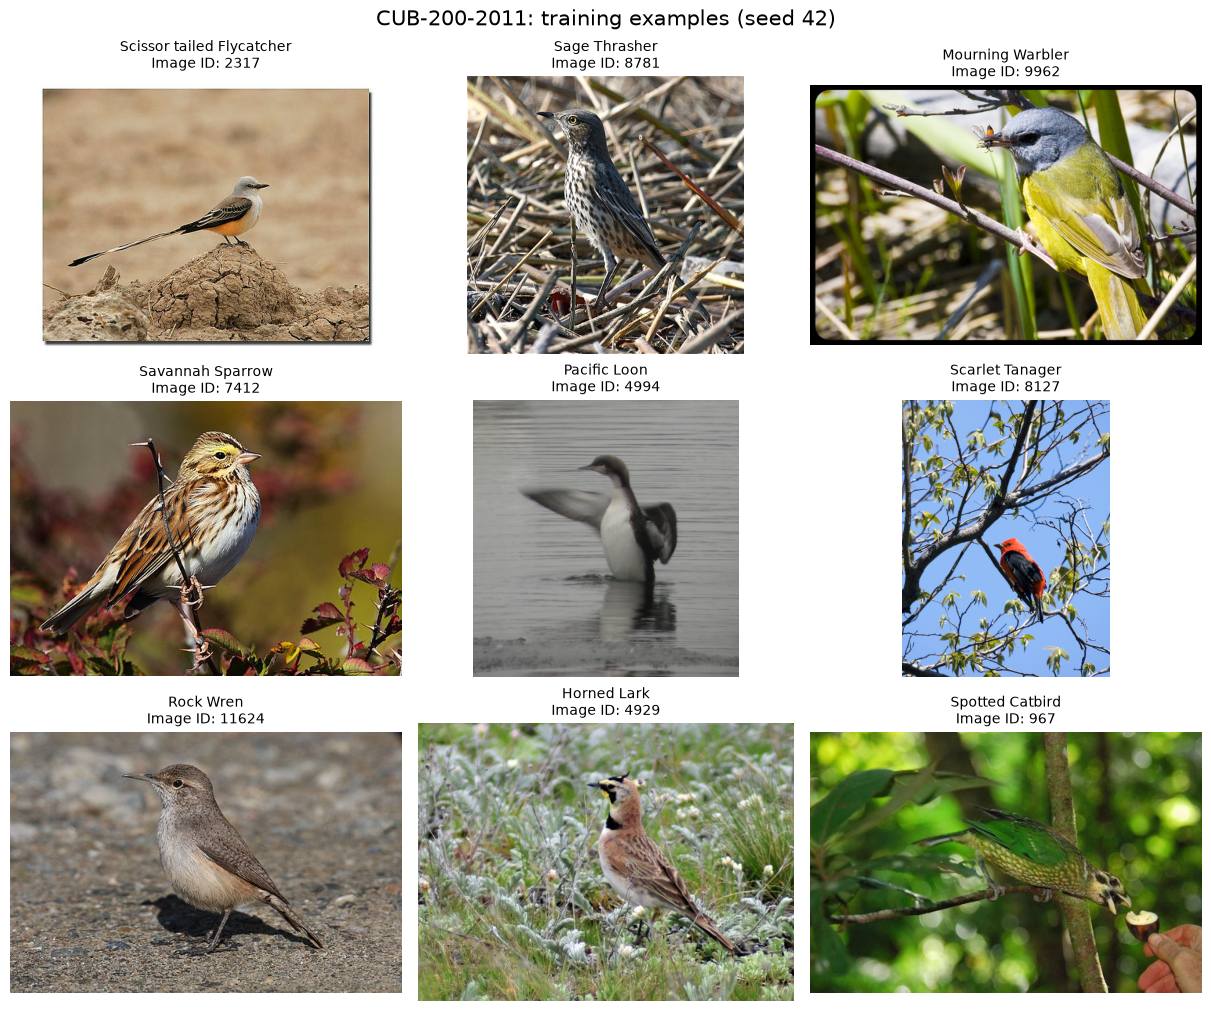

Training preview saved to: C:\Users\dalma\PycharmProjects\MachineLearning_Project\data\training_examples.png


In [6]:
training_rows = manifest.loc[manifest['split'].eq('train')]
rng = np.random.default_rng(SEED)
example_class_ids = rng.choice(
    np.sort(training_rows['class_id'].unique()), size=9, replace=False,
)
example_rows = pd.concat([
    training_rows.loc[training_rows['class_id'].eq(class_id)].sample(
        n=1, random_state=SEED,
    )
    for class_id in example_class_ids
]).reset_index(drop=True)
assert example_rows['split'].eq('train').all()

fig, axes = plt.subplots(3, 3, figsize=(12, 10), layout='constrained')
for axis, row in zip(axes.flat, example_rows.itertuples(index=False)):
    with Image.open(image_file(row.relative_path)) as picture:
        axis.imshow(picture.convert('RGB'))
    species_name = row.class_name.split('.', 1)[1].replace('_', ' ')
    axis.set_title(f'{species_name}\nImage ID: {row.image_id}', fontsize=10)
    axis.axis('off')
fig.suptitle('CUB-200-2011: training examples (seed 42)', fontsize=15)
# This preview contains dataset photographs; it is saved under writable data/.
preview_path = DATA_DIR / 'training_examples.png'
fig.savefig(preview_path, dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Training preview saved to:', preview_path)

## 7. Save the preparation report

Record package versions, hardware context, data checks, counts, and measured preparation times. These timings describe data preparation only; the feature-extraction/classifier resource pilot is the next stage.

The dataset publisher notes possible overlap with ImageNet. A later comparison with pretrained EfficientNet features must acknowledge this limitation and the additional pretraining data.

In [7]:
# Re-read every saved manifest so the report also checks files on disk.
for filename, expected_table in manifest_tables.items():
    saved_table = pd.read_csv(SPLITS_DIR / filename)
    pd.testing.assert_frame_equal(saved_table, expected_table.reset_index(drop=True))
    assert sha256_file(SPLITS_DIR / filename) == split_config['manifest_sha256'][filename]

preparation_report = {
    'prepared_at_utc': datetime.now(timezone.utc).isoformat(),
    'stage': 'dataset preparation; no models trained',
    'environment': environment,
    'dataset': {
        'source': dataset_provenance,
        'archive_name': dataset_provenance['archive_name'],
        'archive_sha256': archive_sha256,
        'images': len(manifest),
        'species': int(manifest['class_id'].nunique()),
        'original_image_modes': image_audit['original_mode'].value_counts().to_dict(),
        'official_counts': official_counts,
        'split_counts': split_config['counts'],
    },
    'checks': {
        'all_images_decoded': len(image_audit) == EXPECTED_IMAGES,
        'image_errors': len(image_errors),
        'duplicate_image_ids': int(manifest['image_id'].duplicated().sum()),
        'exact_duplicate_image_files': len(duplicate_images),
        'exact_duplicate_groups': int(duplicate_images['sha256'].nunique()),
        'duplicate_files_by_split': duplicate_images['split'].value_counts().to_dict(),
        'exact_duplicate_groups_across_splits': int(cross_split_duplicates.sum()),
        'official_test_preserved': True,
        'all_species_in_every_split': bool(class_counts.gt(0).all().all()),
        'saved_manifests_read_back_successfully': True,
    },
    'preparation_timings_seconds': timings,
    'next_stage': 'Training-only resource pilot, then RGB histogram + Logistic Regression baseline.',
}
report_path = CHECKS_DIR / 'preparation_summary.json'
report_path.write_text(json.dumps(preparation_report, indent=2), encoding='utf-8')

print('Data preparation complete.')
display(split_summary)
display(pd.Series(timings, name='seconds').to_frame())
print('Report:', report_path)
print('Next: run a resource pilot on training data and implement the RGB baseline.')

Data preparation complete.


,images,species,minimum_images_per_species,maximum_images_per_species
train,4795,200,23,24
validation,1199,200,5,6
test,5794,200,11,30


,seconds
archive_check_and_extraction_seconds,0.909
metadata_verification_seconds,0.039
image_integrity_seconds,26.647
split_creation_seconds,0.111


Report: C:\Users\dalma\PycharmProjects\MachineLearning_Project\results\data_checks\preparation_summary.json
Next: run a resource pilot on training data and implement the RGB baseline.


## 8. Experiment protocol and dependencies

We compare RGB + Logistic Regression, HSV + Linear SVM, HSV+LBP + Linear SVM, and frozen ImageNet EfficientNet-B0 + Logistic Regression. **Validation macro-F1** selects C from 0.01, 0.1, 1, 10 (ties favour smaller C). All 200 species and the saved splits are retained. Scalers see training data only. Models are not refitted on validation data. Test features and predictions are computed only after all four selections are saved.

On Kaggle, a GPU is recommended for feature extraction. Enable **Internet** for the first pretrained-weight download, or attach the official weight file and set WEIGHTS_FILE below. Other operations require no downloads. Run all cells in order. Feature caches and saved models allow interrupted sessions to resume.

Histograms use full images resized to 128×128 without augmentation or bounding-box crops. EfficientNet uses its published deterministic preprocessing: resize the shorter side to 256, centre-crop 224, ImageNet normalisation. This preserves aspect ratio and is a documented refinement of the proposal's square resize. [Torchvision weights and transforms](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html).

The default EXPERIMENT_SPECIES=200 runs the full project. If the resource pilot justifies the proposal's fallback, set it to 50: 25 warblers, 17 sparrows, and 8 gulls chosen from class names before looking at test performance. Original split assignments are preserved. Each scope has separate manifests, caches, results, and displayed species counts; 50-species scores are not full-dataset scores.

In [ ]:
import warnings
import joblib
import psutil
import torch
import torchvision
from skimage.feature import local_binary_pattern
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

WEIGHTS_FILE = None  # Optional path to official efficientnet_b0_rwightman-7f5810bc.pth.
EXPERIMENT_SPECIES = 200  # 200 = full project; 50 = documented resource fallback.
assert EXPERIMENT_SPECIES in (200, 50)
if EXPERIMENT_SPECIES == 200:
    selected_classes = classes.copy()
else:
    # Fixed taxonomy-only selection, defined before any test evaluation.
    selected_classes = pd.concat([
        classes.loc[classes['class_name'].str.contains(group)].sort_values('class_id').head(count)
        for group, count in [('Warbler', 25), ('Sparrow', 17), ('Gull', 8)]
    ]).sort_values('class_id')
    assert len(selected_classes) == 50
ALL_LABELS = np.sort(selected_classes['class_id'].to_numpy())
experiment_manifest = manifest.loc[manifest['class_id'].isin(ALL_LABELS)].copy()
C_GRID = [0.01, 0.1, 1.0, 10.0]
BATCH_SIZE = 32
THREADS = min(4, os.cpu_count() or 1)
SVM_WORKERS = min(8, os.cpu_count() or 1)
torch.set_num_threads(THREADS)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights = EfficientNet_B0_Weights.IMAGENET1K_V1
cnn_transform = weights.transforms()
experiment_settings = {
    'species_ids': ALL_LABELS.tolist(), 'species_count': len(ALL_LABELS),
    'seed': SEED, 'C_grid': C_GRID, 'selection_metric': 'validation_macro_f1',
    'rgb': '128x128 bilinear; concatenate 16 bins per RGB channel; sum=1',
    'hsv': '128x128 bilinear; PIL HSV; joint 8x8x8 bins; sum=1',
    'lbp': 'PIL grayscale uint8; uniform P=8 R=1; 10 bins; sum=1',
    'cnn_weights': str(weights), 'cnn_transform': str(cnn_transform),
    'batch_size': BATCH_SIZE, 'cpu_threads': THREADS, 'svm_iteration_budget': 2000, 'svm_dual': False, 'svm_workers': SVM_WORKERS, 'svm_strategy': 'threaded one-vs-rest',
    'versions': {name: version(name) for name in [
        'numpy', 'pandas', 'Pillow', 'scikit-image', 'scikit-learn', 'torch', 'torchvision']},
    'manifest_sha256': sha256_file(SPLITS_DIR / 'image_manifest.csv'),
    'image_audit_sha256': sha256_file(CHECKS_DIR / 'image_audit.csv'),
}
run_id = hashlib.sha256(json.dumps(experiment_settings, sort_keys=True).encode()).hexdigest()[:16]
RUN_DIR = PROJECT_ROOT / 'results' / 'experiments' / run_id
FEATURE_DIR = CACHE_DIR / 'features' / run_id
MODEL_DIR = RUN_DIR / 'models'
for folder in (RUN_DIR, FEATURE_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
experiment_hardware = {
    **environment, 'device': str(DEVICE), 'threads': THREADS,
    'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
}
(RUN_DIR / 'settings.json').write_text(json.dumps(experiment_settings, indent=2), encoding='utf-8')
(RUN_DIR / 'hardware.json').write_text(json.dumps(experiment_hardware, indent=2), encoding='utf-8')
experiment_manifest.to_csv(RUN_DIR / 'experiment_manifest.csv', index=False)
frames = {name: experiment_manifest.loc[experiment_manifest['split'].eq(name)].reset_index(drop=True)
          for name in ['train', 'validation', 'test']}
feature_log = (pd.read_csv(RUN_DIR / 'feature_runtimes.csv').to_dict('records')
               if (RUN_DIR / 'feature_runtimes.csv').exists() else [])
models = {}
selection_records = []
search_records = []
print('Species in this experiment:', len(ALL_LABELS))
print('Run:', run_id, '| device:', DEVICE, '| results:', RUN_DIR)

## 9. Deterministic feature extraction and caches

RGB has 48 features; HSV has 512; uniform LBP has 10; HSV+LBP has 522; EfficientNet has 1,280. Configuration 3 reuses exactly the HSV features from Configuration 2. Cache files contain image IDs and are checked against the manifest before reuse. Cached extraction times record the original computation; current cache-load times are logged separately.

The neural network is frozen and in evaluation mode; only its final Logistic Regression classifier is trained. Pretrained weights come from torchvision's official URL and are hash-checked. No random-weight fallback is allowed.

In [ ]:
def histogram_features(rows):
    rgb_values, hsv_values, lbp_values = [], [], []
    for i, row in enumerate(rows.itertuples(index=False)):
        with Image.open(image_file(row.relative_path)) as image:
            rgb_image = image.convert('RGB').resize((128, 128), Image.Resampling.BILINEAR)
            rgb = np.asarray(rgb_image)
            hsv = np.asarray(rgb_image.convert('HSV'))
            gray = np.asarray(rgb_image.convert('L'))
        rgb_hist = np.concatenate([np.histogram(rgb[..., c], bins=16, range=(0, 256))[0]
                                   for c in range(3)]).astype(np.float32)
        hsv_hist = np.histogramdd(hsv.reshape(-1, 3), bins=(8, 8, 8),
                                  range=((0, 256),) * 3)[0].ravel().astype(np.float32)
        lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
        lbp_hist = np.bincount(lbp.astype(np.int64).ravel(), minlength=10).astype(np.float32)
        rgb_values.append(rgb_hist / rgb_hist.sum())
        hsv_values.append(hsv_hist / hsv_hist.sum())
        lbp_values.append(lbp_hist / lbp_hist.sum())
        if (i + 1) % 1000 == 0:
            print(f'Histograms: {i + 1:,}/{len(rows):,}', flush=True)
    return {'rgb': np.asarray(rgb_values), 'hsv': np.asarray(hsv_values),
            'lbp': np.asarray(lbp_values)}


torch.hub.set_dir(str(CACHE_DIR / 'torch'))
checkpoint_dir = Path(torch.hub.get_dir()) / 'checkpoints'
checkpoint_dir.mkdir(parents=True, exist_ok=True)
weight_name = weights.url.rsplit('/', 1)[1]
weight_path = Path(WEIGHTS_FILE) if WEIGHTS_FILE else checkpoint_dir / weight_name
if WEIGHTS_FILE is None and not weight_path.exists() and RUNTIME == 'kaggle':
    attached_weights = sorted(INPUT_ROOT.rglob(weight_name))
    if len(attached_weights) == 1:
        weight_path = attached_weights[0]
if not weight_path.exists():
    if WEIGHTS_FILE:
        raise FileNotFoundError(f'Weight file not found: {weight_path}')
    try:
        torch.hub.download_url_to_file(weights.url, str(weight_path), hash_prefix='7f5810bc')
    except Exception as error:
        raise RuntimeError('Enable Kaggle Internet for the official weight download, or attach '
                           f'{weight_name} and set WEIGHTS_FILE. Original error: {error}') from error
weight_digest = sha256_file(weight_path)
assert weight_digest.startswith('7f5810bc'), 'Unexpected pretrained weights; use the official checkpoint.'
backbone = efficientnet_b0(weights=None)
backbone.load_state_dict(torch.load(weight_path, map_location='cpu', weights_only=True))
backbone.classifier = torch.nn.Identity()
backbone.requires_grad_(False)
backbone.eval().to(DEVICE)
(RUN_DIR / 'pretrained_resource.json').write_text(json.dumps({
    'url': weights.url, 'sha256': weight_digest, 'weights': str(weights),
    'feature_dimension': 1280, 'frozen': True, 'transform': str(cnn_transform),
}, indent=2), encoding='utf-8')


def cnn_features(rows):
    vectors = []
    with torch.inference_mode():
        for start in range(0, len(rows), BATCH_SIZE):
            tensors = []
            for row in rows.iloc[start:start + BATCH_SIZE].itertuples(index=False):
                with Image.open(image_file(row.relative_path)) as image:
                    tensors.append(cnn_transform(image.convert('RGB')))
            batch = torch.stack(tensors).to(DEVICE)
            vectors.append(backbone(batch).cpu().numpy())
            if (start // BATCH_SIZE) % 20 == 0:
                print(f'CNN: {min(start + BATCH_SIZE, len(rows)):,}/{len(rows):,}', flush=True)
    return {'cnn': np.concatenate(vectors).astype(np.float32)}


def cached_features(family, split):
    rows = frames[split]
    path = FEATURE_DIR / f'{family}_{split}.npz'
    started = perf_counter()
    cached = path.exists()
    if cached:
        with np.load(path, allow_pickle=False) as saved:
            assert np.array_equal(saved['image_ids'], rows['image_id'].to_numpy()), 'Cache ID mismatch.'
            values = {key: saved[key] for key in saved.files if key not in ['image_ids', 'seconds']}
            extraction_seconds = float(saved['seconds'])
    else:
        values = histogram_features(rows) if family == 'hist' else cnn_features(rows)
        extraction_seconds = perf_counter() - started
        temporary = path.with_suffix('.partial.npz')
        np.savez_compressed(temporary, image_ids=rows['image_id'].to_numpy(),
                            seconds=extraction_seconds, **values)
        temporary.replace(path)
    for name, array in values.items():
        assert len(array) == len(rows) and np.isfinite(array).all()
    feature_log[:] = [entry for entry in feature_log
                      if (entry['family'], entry['split']) != (family, split)]
    feature_log.append({'family': family, 'split': split, 'cached': cached,
                        'extraction_seconds': extraction_seconds,
                        'current_call_seconds': perf_counter() - started,
                        'feature_bytes': sum(array.nbytes for array in values.values())})
    pd.DataFrame(feature_log).to_csv(RUN_DIR / 'feature_runtimes.csv', index=False)
    return values

## 10. Resource pilot (training data only)

Measure extraction on a fixed training sample and linear-classifier fitting on two training images per species. Extrapolated extraction times are approximate, not full-run timings. RSS is a process-memory snapshot, not peak memory. Keep all 200 species for the main experiments; the pilot documents feasibility rather than choosing species using performance.

In [ ]:
pilot_rows = frames['train'].groupby('class_id', sort=True).head(2).reset_index(drop=True)
sample_rows = pilot_rows.sample(n=64, random_state=SEED).reset_index(drop=True)
pilot_results = []
for family, extractor in [('hist', histogram_features), ('cnn', cnn_features)]:
    started = perf_counter()
    measured = extractor(sample_rows)
    seconds = perf_counter() - started
    pilot_results.append({'operation': family, 'images': len(sample_rows), 'seconds': seconds,
                          'estimated_all_images_seconds': seconds * len(experiment_manifest) / len(sample_rows),
                          'rss_mb': psutil.Process().memory_info().rss / 2**20})
pilot_hist = histogram_features(pilot_rows)
started = perf_counter()
with threadpool_limits(limits=THREADS):
    LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000, random_state=SEED).fit(
        pilot_hist['rgb'], pilot_rows['class_id'])
pilot_results.append({'operation': f'{len(ALL_LABELS)}-class RGB classifier (2 training images per species)',
                      'images': len(pilot_rows), 'seconds': perf_counter() - started,
                      'estimated_all_images_seconds': None,
                      'rss_mb': psutil.Process().memory_info().rss / 2**20})
pilot_table = pd.DataFrame(pilot_results)
pilot_table.to_csv(RUN_DIR / 'resource_pilot.csv', index=False)
display(pilot_table)
print(f'Proceeding with {len(ALL_LABELS)} species; later caches save repeated extraction.')

## 11. Baseline and validation comparisons

Run the RGB baseline first, then add colour/texture and CNN representations. Each configuration uses identical image assignments. C is selected by validation macro-F1 only. The scaler is inside the estimator pipeline and is fitted only on training rows.

Every grid trial, fit duration, convergence status, and validation metric is saved. SVM trials have a fixed 2,000-iteration budget; Logistic Regression can retry with 10,000 iterations. Unconverged settings are recorded and excluded from selection. If no setting converges, that configuration stops evaluation. Both SVM configurations use the same grid, iteration budget, and convergence rule. Test labels are not used here. Saved estimators belong to this exact settings/data fingerprint.

In [ ]:
def score_predictions(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=ALL_LABELS, average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(y_true, y_pred)), 'macro_precision': float(precision),
            'macro_recall': float(recall), 'macro_f1': float(f1)}


def make_classifier(name, c, max_iter):
    if name in ['HSV_SVM', 'HSV_LBP_SVM']:
        classifier = OneVsRestClassifier(
            LinearSVC(C=c, dual=False, max_iter=max_iter, random_state=SEED), n_jobs=SVM_WORKERS)
    else:
        classifier = LogisticRegression(C=c, solver='lbfgs', max_iter=max_iter, random_state=SEED)
    return classifier if name == 'RGB_LR' else make_pipeline(StandardScaler(), classifier)


def select_model(name, x_train, x_validation):
    model_path = MODEL_DIR / f'{name}.joblib'
    selection_path = MODEL_DIR / f'{name}_selection.json'
    trials_path = RUN_DIR / f'{name}_validation_trials.csv'
    if model_path.exists() and selection_path.exists() and trials_path.exists():
        models[name] = joblib.load(model_path)  # Only our own locally generated artifacts.
        selected = json.loads(selection_path.read_text(encoding='utf-8'))
        trials = pd.read_csv(trials_path).to_dict('records')
        print(name, 'restored selection, C =', selected['C'])
    else:
        trials, candidates = [], {}
        for c in C_GRID:
            total_seconds = 0.0
            budgets = (2000,) if name in ['HSV_SVM', 'HSV_LBP_SVM'] else (2000, 10000)
            for max_iter in budgets:
                estimator = make_classifier(name, c, max_iter)
                print(f'Fitting {name}: C={c}, iteration limit={max_iter}', flush=True)
                started = perf_counter()
                with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=THREADS), joblib.parallel_backend('threading'):
                    warnings.simplefilter('always', ConvergenceWarning)
                    estimator.fit(x_train, frames['train']['class_id'].to_numpy())
                total_seconds += perf_counter() - started
                converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
                if converged:
                    break
            if not converged:
                trials.append({'model': name, 'C': c, 'fit_seconds': total_seconds,
                               'max_iter': max_iter, 'converged': False,
                               'accuracy': np.nan, 'macro_precision': np.nan,
                               'macro_recall': np.nan, 'macro_f1': np.nan})
                print(f'{name}: C={c} excluded because the solver did not converge.', flush=True)
                continue
            with threadpool_limits(limits=THREADS):
                predicted = estimator.predict(x_validation)
            trial = {'model': name, 'C': c, 'fit_seconds': total_seconds,
                     'max_iter': max_iter, 'converged': converged,
                     **score_predictions(frames['validation']['class_id'], predicted)}
            trials.append(trial)
            candidates[c] = estimator
            print(name, 'C =', c, '| validation macro-F1 =', round(trial['macro_f1'], 4), flush=True)
        pd.DataFrame(trials).to_csv(trials_path, index=False)
        if not candidates:
            raise RuntimeError(f'{name}: no setting converged. Inspect saved trials before continuing.')
        selected = max((trial for trial in trials if trial['converged']),
                       key=lambda trial: (trial['macro_f1'], -trial['C']))
        models[name] = candidates[selected['C']]
        temporary = model_path.with_suffix('.partial.joblib')
        joblib.dump(models[name], temporary)
        temporary.replace(model_path)
        pd.DataFrame(trials).to_csv(trials_path, index=False)
        selection_path.write_text(json.dumps(selected, indent=2), encoding='utf-8')
    selection_records[:] = [record for record in selection_records if record['model'] != name]
    search_records[:] = [record for record in search_records if record['model'] != name]
    selection_records.append(selected)
    search_records.extend(trials)
    pd.DataFrame(selection_records).to_csv(RUN_DIR / 'validation_selection.csv', index=False)
    return selected

In [ ]:
hist_train = cached_features('hist', 'train')
hist_validation = cached_features('hist', 'validation')
baseline_selection = select_model('RGB_LR', hist_train['rgb'], hist_validation['rgb'])
display(pd.DataFrame([baseline_selection]))

In [ ]:
select_model('HSV_SVM', hist_train['hsv'], hist_validation['hsv'])
select_model('HSV_LBP_SVM',
             np.concatenate([hist_train['hsv'], hist_train['lbp']], axis=1),
             np.concatenate([hist_validation['hsv'], hist_validation['lbp']], axis=1))
display(pd.DataFrame(selection_records))

## 12. Frozen EfficientNet feature classifier

Extract features once, cache them, and tune a scaled multinomial Logistic Regression classifier. The backbone remains unchanged. CPU execution is supported; GPU execution is faster. Saved caches can be reused on subsequent runs with the same settings.

In [ ]:
cnn_train = cached_features('cnn', 'train')['cnn']
cnn_validation = cached_features('cnn', 'validation')['cnn']
assert cnn_train.shape[1] == 1280
select_model('EfficientNet_LR', cnn_train, cnn_validation)
validation_comparison = pd.DataFrame(selection_records).set_index('model')
display(validation_comparison)
assert len(models) == 4
locked_selection = {
    'run_id': run_id, 'selection_metric': 'validation_macro_f1',
    'selected_C': {name: float(validation_comparison.loc[name, 'C']) for name in models},
    'model_sha256': {name: sha256_file(MODEL_DIR / f'{name}.joblib') for name in models},
    'test_used_for_selection': False,
}
(RUN_DIR / 'locked_selection.json').write_text(json.dumps(locked_selection, indent=2), encoding='utf-8')
# Select a readable taxonomy group before examining any test errors.
warbler_ids = selected_classes.loc[selected_classes['class_name'].str.contains('Warbler'), 'class_id'].head(10).tolist()
assert len(warbler_ids) == 10
print('All four configurations locked. Final test evaluation follows.')

## 13. Final held-out evaluation

Evaluate the four locked models on the official test set. Never tune settings after inspecting these results. Test predictions are saved with image IDs and reused on reruns; their model hashes must match the locked selection. Report Top-1 accuracy and macro precision/recall/F1 across all 200 species.

The colour-versus-texture comparison holds the classifier family, scaler procedure, splits, and C grid fixed. Its observed difference answers the investigation; an improvement is not assumed.

In [ ]:
assert len(models) == 4 and (RUN_DIR / 'locked_selection.json').exists()
prediction_path = RUN_DIR / 'test_predictions.csv'
receipt_path = RUN_DIR / 'test_evaluation_receipt.json'
if prediction_path.exists():
    receipt = json.loads(receipt_path.read_text(encoding='utf-8'))
    assert receipt['locked_selection'] == locked_selection, 'Saved predictions use different models.'
    predictions = pd.read_csv(prediction_path)
    assert np.array_equal(predictions['image_id'], frames['test']['image_id'])
    assert np.array_equal(predictions['true_class_id'], frames['test']['class_id'])
    assert sha256_file(prediction_path) == receipt['predictions_sha256']
    print('Reusing saved final test predictions.')
else:
    hist_test = cached_features('hist', 'test')
    cnn_test = cached_features('cnn', 'test')['cnn']
    test_arrays = {
        'RGB_LR': hist_test['rgb'], 'HSV_SVM': hist_test['hsv'],
        'HSV_LBP_SVM': np.concatenate([hist_test['hsv'], hist_test['lbp']], axis=1),
        'EfficientNet_LR': cnn_test,
    }
    predictions = frames['test'][['image_id', 'class_id']].rename(columns={'class_id': 'true_class_id'}).copy()
    for name, estimator in models.items():
        assert sha256_file(MODEL_DIR / f'{name}.joblib') == locked_selection['model_sha256'][name]
        with threadpool_limits(limits=THREADS):
            predictions[name] = estimator.predict(test_arrays[name])
    predictions.to_csv(prediction_path, index=False)
    receipt_path.write_text(json.dumps({
        'locked_selection': locked_selection,
        'predictions_sha256': sha256_file(prediction_path),
        'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
    }, indent=2), encoding='utf-8')

comparison = pd.DataFrame([
    {'model': name, 'C': locked_selection['selected_C'][name],
     **score_predictions(predictions['true_class_id'], predictions[name]),
     'selected_fit_seconds': float(validation_comparison.loc[name, 'fit_seconds']),
     'total_tuning_fit_seconds': sum(t['fit_seconds'] for t in search_records if t['model'] == name)}
    for name in models
]).set_index('model')
comparison.to_csv(RUN_DIR / 'test_metrics.csv')
display(comparison)
texture_delta = comparison.loc['HSV_LBP_SVM', 'macro_f1'] - comparison.loc['HSV_SVM', 'macro_f1']
print(f'Adding LBP changes test macro-F1 by {texture_delta:+.4f} ({100 * texture_delta:+.2f} percentage points).')
ax = comparison[['accuracy', 'macro_f1']].plot.bar(figsize=(9, 4), ylim=(0, 1), rot=15)
ax.set_ylabel('Score')
ax.set_title(f'Final test performance across {len(ALL_LABELS)} species')
ax.figure.tight_layout()
ax.figure.savefig(RUN_DIR / 'model_comparison.png', dpi=160)
plt.show()
plt.close(ax.figure)

## 14. Confusion matrices and prediction examples

Save full 200×200 confusion matrices and per-class metrics. The readable plots use the ten warbler species selected above, with an **Other prediction** column so errors outside the displayed group remain visible. Rows are normalised over all test images of the true species.

The example grids show up to three correct and three incorrect predictions per model, selected with seed 42. Selection is descriptive and does not change models. Inspect posture, bird size, plumage, occlusion, and background; an image alone does not prove why a model failed.

In [ ]:
class_names = classes.set_index('class_id')['class_name'].to_dict()
def species_name(class_id):
    return class_names[int(class_id)].split('.', 1)[1].replace('_', ' ')

confusion_pairs = []
example_records = []
for name in models:
    true = predictions['true_class_id'].to_numpy()
    predicted = predictions[name].to_numpy()
    cm = confusion_matrix(true, predicted, labels=ALL_LABELS)
    pd.DataFrame(cm, index=ALL_LABELS, columns=ALL_LABELS).to_csv(RUN_DIR / f'{name}_confusion_full.csv')
    pd.DataFrame(classification_report(
        true, predicted, labels=ALL_LABELS, target_names=[species_name(c) for c in ALL_LABELS],
        output_dict=True, zero_division=0,
    )).T.to_csv(RUN_DIR / f'{name}_per_class.csv')
    label_positions = {label: i for i, label in enumerate(ALL_LABELS)}
    selected_rows = np.array([label_positions[label] for label in warbler_ids])
    small = cm[np.ix_(selected_rows, selected_rows)]
    other = cm[selected_rows].sum(axis=1) - small.sum(axis=1)
    shown = np.column_stack([small, other]).astype(float)
    shown /= cm[selected_rows].sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(11, 7))
    view = ax.imshow(shown, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(11), [species_name(c) for c in warbler_ids] + ['Other prediction'], rotation=70, ha='right')
    ax.set_yticks(range(10), [species_name(c) for c in warbler_ids])
    ax.set(xlabel='Predicted species', ylabel='True species', title=f'{name}: warbler test confusion')
    fig.colorbar(view, ax=ax, label='Fraction of true-species test images')
    fig.tight_layout()
    fig.savefig(RUN_DIR / f'{name}_warbler_confusion.png', dpi=150)
    plt.show()
    plt.close(fig)
    wrong_cm = cm.copy()
    np.fill_diagonal(wrong_cm, 0)
    for flat in np.argsort(wrong_cm.ravel())[-5:][::-1]:
        a, b = np.unravel_index(flat, wrong_cm.shape)
        if wrong_cm[a, b]:
            confusion_pairs.append({'model': name, 'true_species': species_name(ALL_LABELS[a]),
                                    'predicted_species': species_name(ALL_LABELS[b]), 'count': int(wrong_cm[a, b])})
    rng = np.random.default_rng(SEED)
    example_indices = []
    for correct in [True, False]:
        candidates = np.flatnonzero((predicted == true) == correct)
        example_indices.extend(rng.choice(candidates, size=min(3, len(candidates)), replace=False).tolist())
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, example_indices):
        row = frames['test'].iloc[index]
        with Image.open(image_file(row.relative_path)) as picture:
            ax.imshow(picture.convert('RGB'))
        ax.set_title(f'True: {species_name(true[index])}\nPred: {species_name(predicted[index])}\nID {row.image_id}',
                     fontsize=9, color='green' if true[index] == predicted[index] else 'red')
        example_records.append({'model': name, 'image_id': int(row.image_id),
                                'true_species': species_name(true[index]),
                                'predicted_species': species_name(predicted[index]),
                                'correct': bool(true[index] == predicted[index]),
                                'pose_background_plumage_notes': ''})
    fig.suptitle(name + ': correct and incorrect test examples')
    # These figures contain dataset photographs.
    fig.savefig(DATA_DIR / f'{name}_prediction_examples.png', dpi=130)
    plt.show()
    plt.close(fig)
pair_table = pd.DataFrame(confusion_pairs)
pair_table.to_csv(RUN_DIR / 'top_confusion_pairs.csv', index=False)
review_path = RUN_DIR / 'example_review.csv'
if not review_path.exists():
    pd.DataFrame(example_records).to_csv(review_path, index=False)
display(pair_table)

## 15. Results interpretation, limitations, and reproduction

The following summary is calculated from the measured scores. Use the image grids and per-class reports to explain differences; do not assume CNN or texture features must win. Add your own visual observations in the preserved example-review CSV before preparing the presentation.

Global histograms discard spatial arrangement and include backgrounds. LBP summarises local texture without locating the bird. Frozen CNN features come from large-scale external ImageNet training, so this is not an equal-training-data comparison. CUB's publisher warns of possible ImageNet image overlap. Other limitations are small per-class training sets, one fixed split/seed, potential near-duplicates not detected by exact hashes, and the lack of independent external evaluation. Score differences from this single split are descriptive, not a statistical significance claim. Only the HSV-versus-HSV+LBP comparison isolates added texture under the shared tuning protocol; RGB-versus-HSV also changes the classifier and histogram design.

References: [CUB dataset](https://www.vision.caltech.edu/datasets/cub_200_2011/), [uniform LBP implementation](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.local_binary_pattern), [scikit-learn](https://scikit-learn.org/stable/), [EfficientNet weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html). No pretrained CNN is fine-tuned. No bounding-box annotations or random augmentations are used. NABirds remains optional.

In [ ]:
ranking = comparison.sort_values('macro_f1', ascending=False)
best_name = ranking.index[0]
summary_lines = [
    f'Run {run_id}: {len(experiment_manifest)} images, {len(ALL_LABELS)} species; seed {SEED}.',
    f'Splits: {len(frames["train"])} training / {len(frames["validation"])} validation / {len(frames["test"])} test.',
    f'Highest measured test macro-F1: {best_name} = {ranking.iloc[0].macro_f1:.4f}.',
    f'RGB baseline test macro-F1: {comparison.loc["RGB_LR", "macro_f1"]:.4f}.',
    f'HSV+LBP minus HSV test macro-F1: {texture_delta:+.4f}.',
    f'EfficientNet minus RGB test macro-F1: {comparison.loc["EfficientNet_LR", "macro_f1"] - comparison.loc["RGB_LR", "macro_f1"]:+.4f}.',
    'Selections used validation macro-F1 only; final test predictions are saved.',
    'Interpret the top confusion pairs and sampled images before claiming visual causes.',
    'Limitations: single split, small per-class samples, background correlations, possible ImageNet overlap.',
]
summary_text = '\n'.join(summary_lines)
(RUN_DIR / 'results_summary.txt').write_text(summary_text, encoding='utf-8')
print(summary_text)
display(pd.DataFrame(feature_log))
print('Histogram extraction times cover the shared RGB, HSV, and LBP pass together.')
print('Experiment artifacts:', RUN_DIR)
print('Image examples:', DATA_DIR)
print('Run All reproduces the workflow; keep caches/models to resume or repeat saved evaluations.')